In [81]:
from datasets import load_dataset
import nltk
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/ninahew/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [82]:
# Write a function that takes an integer x and two languages, and returns shared word analysis across x number of wikipedia articles

def analyse_lang(x, lang):
    lang_ds = load_dataset("wikimedia/wikipedia", "20231101.{lang}".format(lang=lang))
    print('dataset ' + '{lang}'.format(lang=lang) + ' loaded')
    # Consider returning number of rows in datasets
    corpus_lang = lang_ds['train']['text'][0:x]
    # print(corpus_lang)
    # Convert to big string
    string_lang = " ".join(corpus_lang)
    tokenized_lang= word_tokenize(string_lang)
    # print("{lang}".format(lang=lang) + " after tokenisation")
    # print("{lang}".format(lang=lang), " : ", str(len(tokenized_lang)), " words")
    # Remove punctuation, proper nouns and numerical entries
    cleaned_lang = [word for word in tokenized_lang if ((len(word) > 2) and (not(word[0].isupper())) and (not(word.isnumeric())))]
    # print("{lang}".format(lang=lang) + " after data cleaning")
    # print("{lang}".format(lang=lang), " : ", str(len(cleaned_lang)), " words")
    dict_lang = {}
    for word in cleaned_lang:
        if word not in dict_lang:
            dict_lang[word] = 0
        dict_lang[word] += 1
    return dict_lang


# Generate Shared word analysis
def shared_word_analysis(x,lang_1, lang_2):
    lang_1_analysed = analyse_lang(x,lang_1)
    lang_2_analysed = analyse_lang(x,lang_2)
    lang_1_col_name = 'word_freq_{lang_1}'.format(lang_1=lang_1)
    lang_1_df = pd.DataFrame.from_dict(lang_1_analysed, orient='index', columns=[lang_1_col_name])
    # print(lang_1_df.sort_values(by = ['word_freq_{lang_1}'.format(lang_1=lang_1)], ascending= False).head(10))
    lang_2_col_name = 'word_freq_{lang_2}'.format(lang_2=lang_2)
    lang_2_df = pd.DataFrame.from_dict(lang_2_analysed, orient='index', columns = [lang_2_col_name])
    # print(lang_2_df.sort_values(by = ['word_freq_{lang_2}'.format(lang_2=lang_2)], ascending= False).head(10))
    shared_words = pd.merge(lang_1_df, lang_2_df, how = 'inner', left_index=True, right_index=True)
    print(str(shared_words.size), " words shared between both languages")
    sns.set_theme(rc={'figure.figsize':(16,6)})
    sns.set_theme(style="darkgrid", context="paper")
    sns.color_palette("Spectral", as_cmap=True)
    # print(shared_words)
    # display(shared_words.head(20))
    # print(type(shared_words))
    # compare_plot = sns.lineplot(data = shared_words, sort = True)
    # plt.show()
    # compare_plot.set_xticklabels(compare_plot.get_xticklabels(), rotation=90)
    shared_words_top_100 = shared_words.nlargest(100, columns = [lang_1_col_name, lang_2_col_name])
    # print('Top 100 most shared words')
    # display(shared_words_top_100)
    shared_100_plot = sns.lineplot(data = shared_words_top_100, sort = True)
    shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)
    return shared_100_plot



In [83]:
# print(analyse_lang(1, 'nl'))

dataset af loaded
dataset nl loaded
158  words shared between both languages


/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_1788/1910315463.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)


<Axes: >

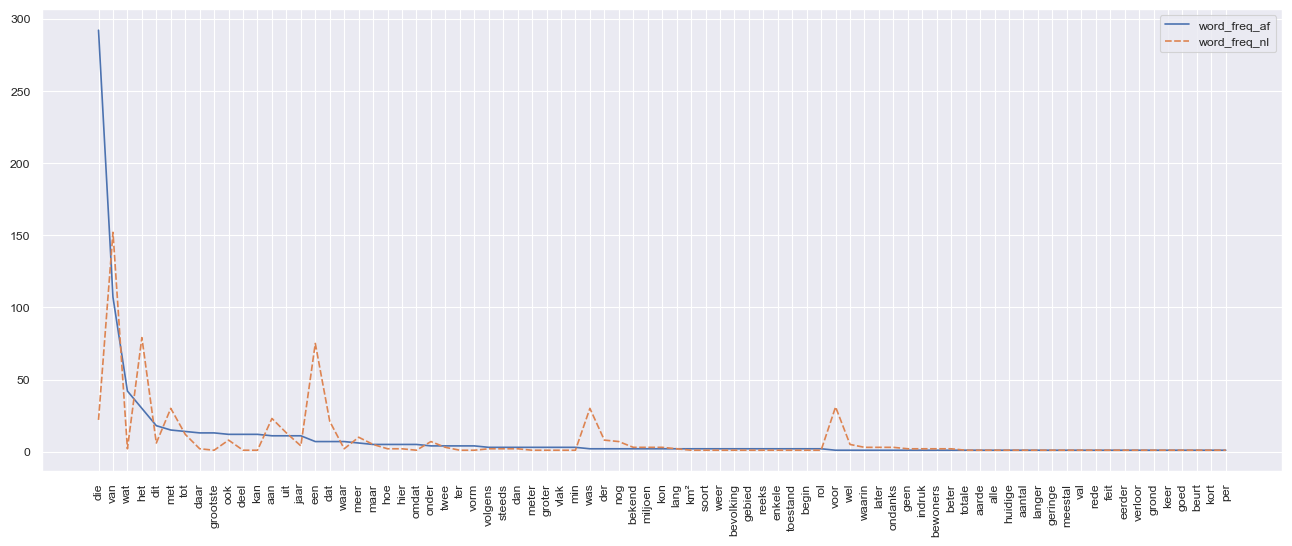

In [84]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.colheader_justify', 'center')
pd.set_option('display.precision', 2)
# display(df)

# Shared words across 1 wikipedia article each
shared_word_analysis(1,'af','nl')

In [85]:
# Tested bg and mk which are mutually intelligible


dataset af loaded
dataset nl loaded
4856  words shared between both languages


/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_1788/1910315463.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)


Axes(0.125,0.11;0.775x0.77)


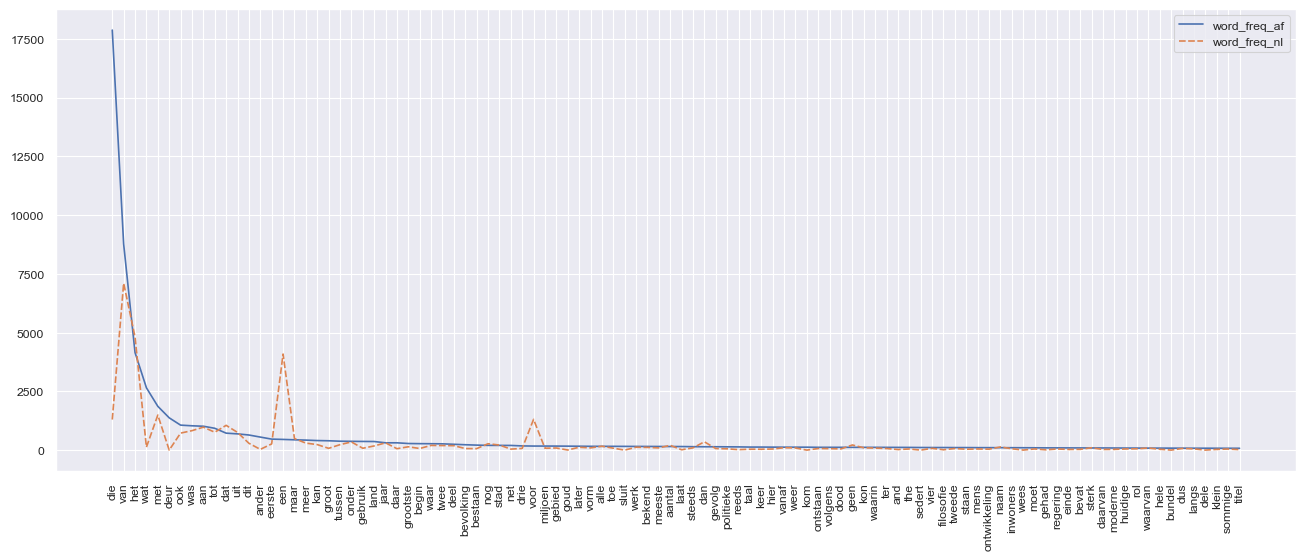

In [86]:
# Shared words across 100 Wikipedia articles

print(shared_word_analysis(100, 'af','nl'))

dataset af loaded
dataset nl loaded
11748  words shared between both languages


/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_1788/1910315463.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)


Axes(0.125,0.11;0.775x0.77)


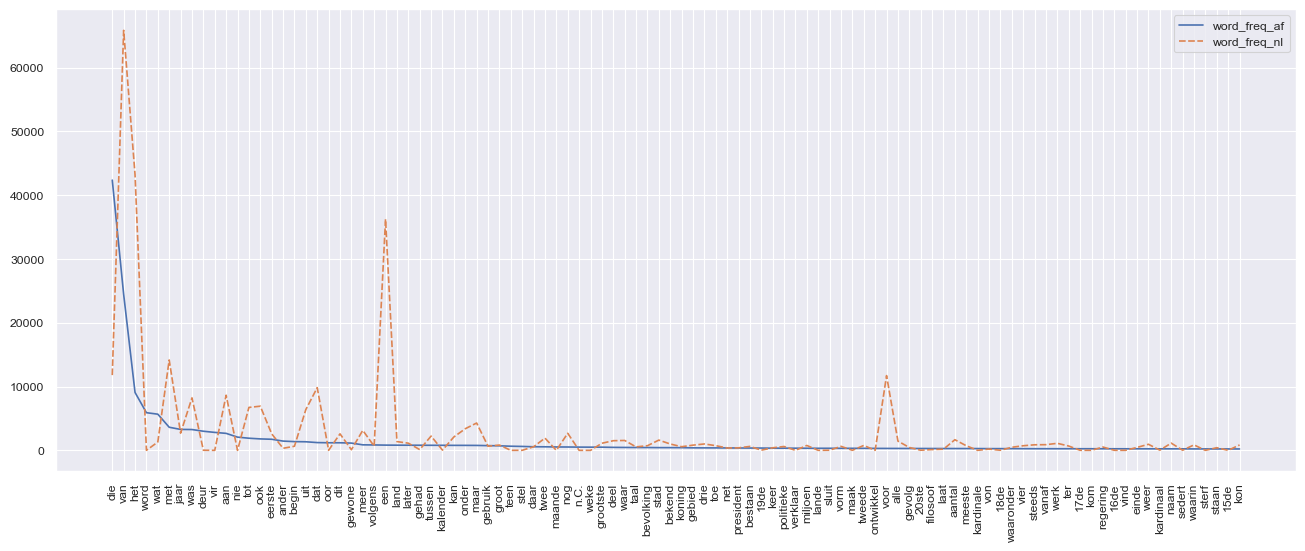

In [87]:
# Shared words acc

print(shared_word_analysis(1000, 'af','nl'))

dataset af loaded
dataset nl loaded
60054  words shared between both languages


/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_1788/1910315463.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)


Axes(0.125,0.11;0.775x0.77)


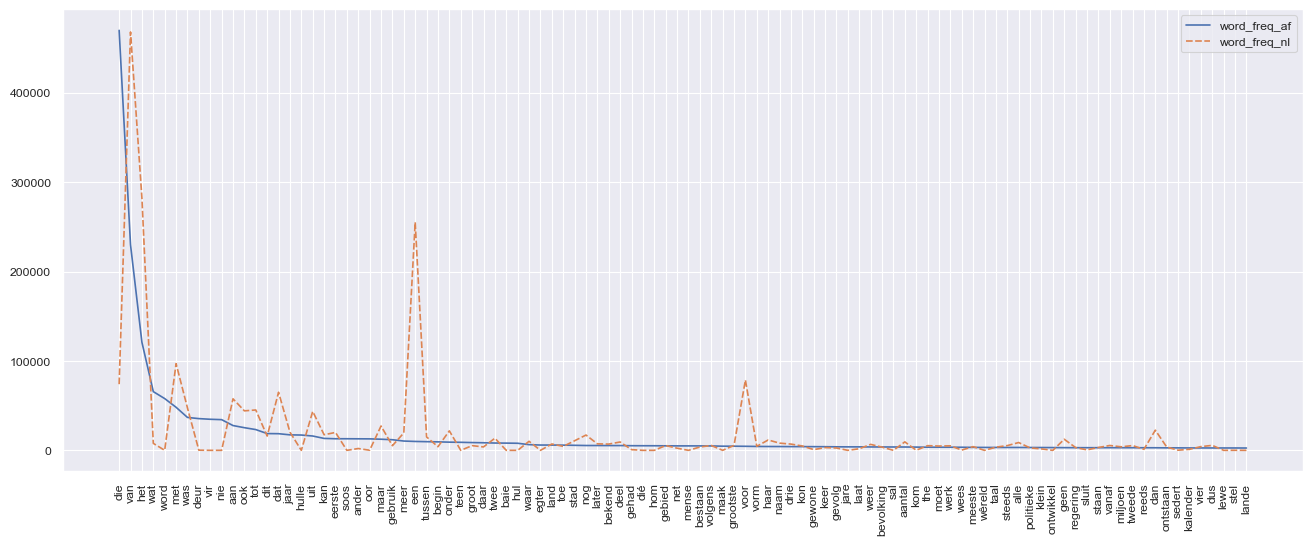

In [88]:
print(shared_word_analysis(10000, 'af','nl'))

TESTING NL AND VLS

dataset vls loaded
dataset nl loaded
346  words shared between both languages


/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_1788/1910315463.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)


Axes(0.125,0.11;0.775x0.77)


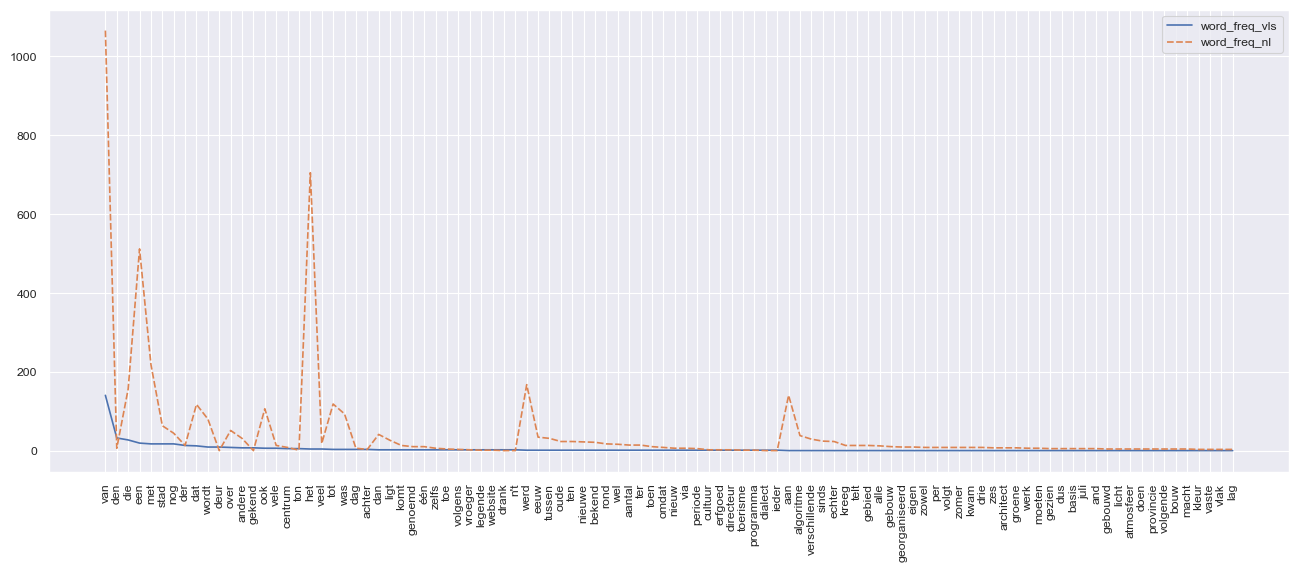

In [90]:
print(shared_word_analysis(10, 'vls','nl'))


dataset nl loaded
dataset vls loaded
346  words shared between both languages
Axes(0.125,0.11;0.775x0.77)


/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_1788/1910315463.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  shared_100_plot.set_xticklabels(shared_100_plot.get_xticklabels(), rotation=90)


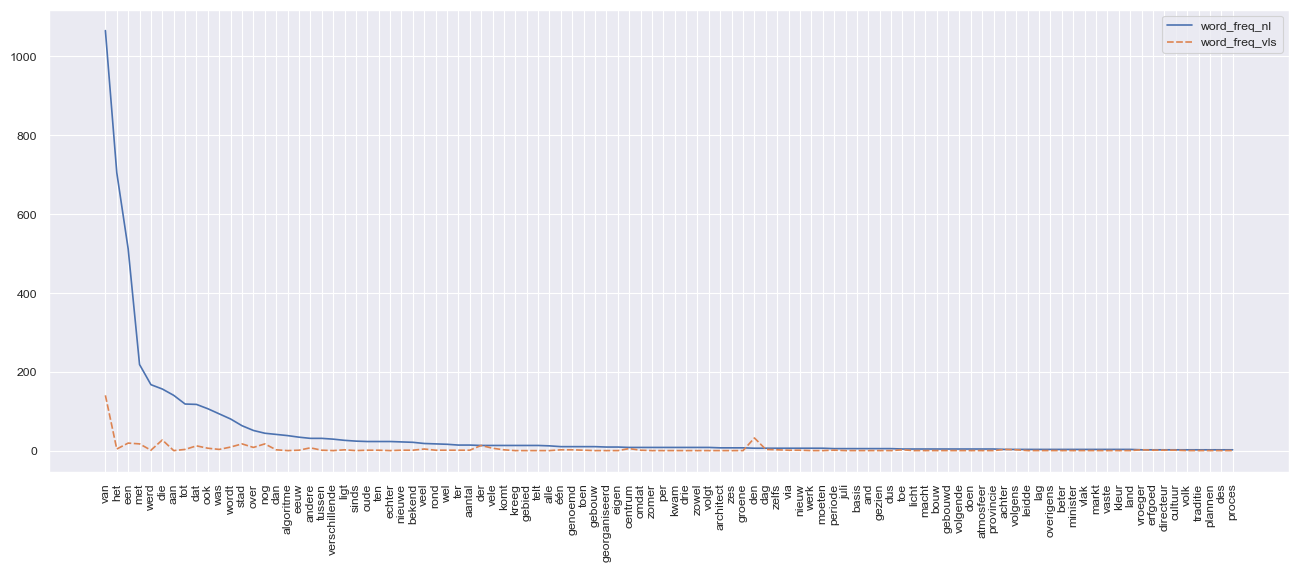

In [91]:
# Plotting the other way around

print(shared_word_analysis(10,'nl', 'vls'))
